In [7]:
%load_ext autoreload
%autoreload 2
from src.utils import load_processed
from src.train import train_baselines

In [ ]:
from tqdm import tqdm
from src.utils import load_processed
from src.train import tune_all
from src.evaluation import plot_confusion_matrices, plot_roc_curves

x_train, x_test, y_train, y_test = load_processed("stats")

results, tuned = tune_all(x_train, y_train, x_test, y_test)
results

,cv_f1_macro,accuracy,balanced_acc,precision_macro,recall_macro,f1_macro,auc,search_time_s,best_params
model,,,,,,,,,
svm,0.982980,0.988662,0.988704,0.988623,0.988704,0.988658,0.999383,0.552544,"{'clf__C': 100, 'clf__gamma': 0.1, 'clf__kerne..."
knn,0.978440,0.986395,0.986481,0.986341,0.986481,0.986391,0.999444,4.631041,"{'clf__n_neighbors': 3, 'clf__p': 1, 'clf__wei..."
random_forest,0.984692,0.977324,0.977407,0.977270,0.977407,0.977319,0.998827,20.499171,"{'clf__max_depth': 8, 'clf__max_features': 0.5..."
decision_tree,0.967676,0.961451,0.961759,0.961626,0.961759,0.961450,0.961759,0.401335,"{'clf__criterion': 'entropy', 'clf__max_depth'..."
logistic_regression,0.941505,0.943311,0.942963,0.943986,0.942963,0.943236,0.978416,0.077932,{'clf__C': 100}
naive_bayes,0.743015,0.750567,0.746667,0.791409,0.746667,0.739474,0.858621,0.061417,{'clf__var_smoothing': 1e-11}


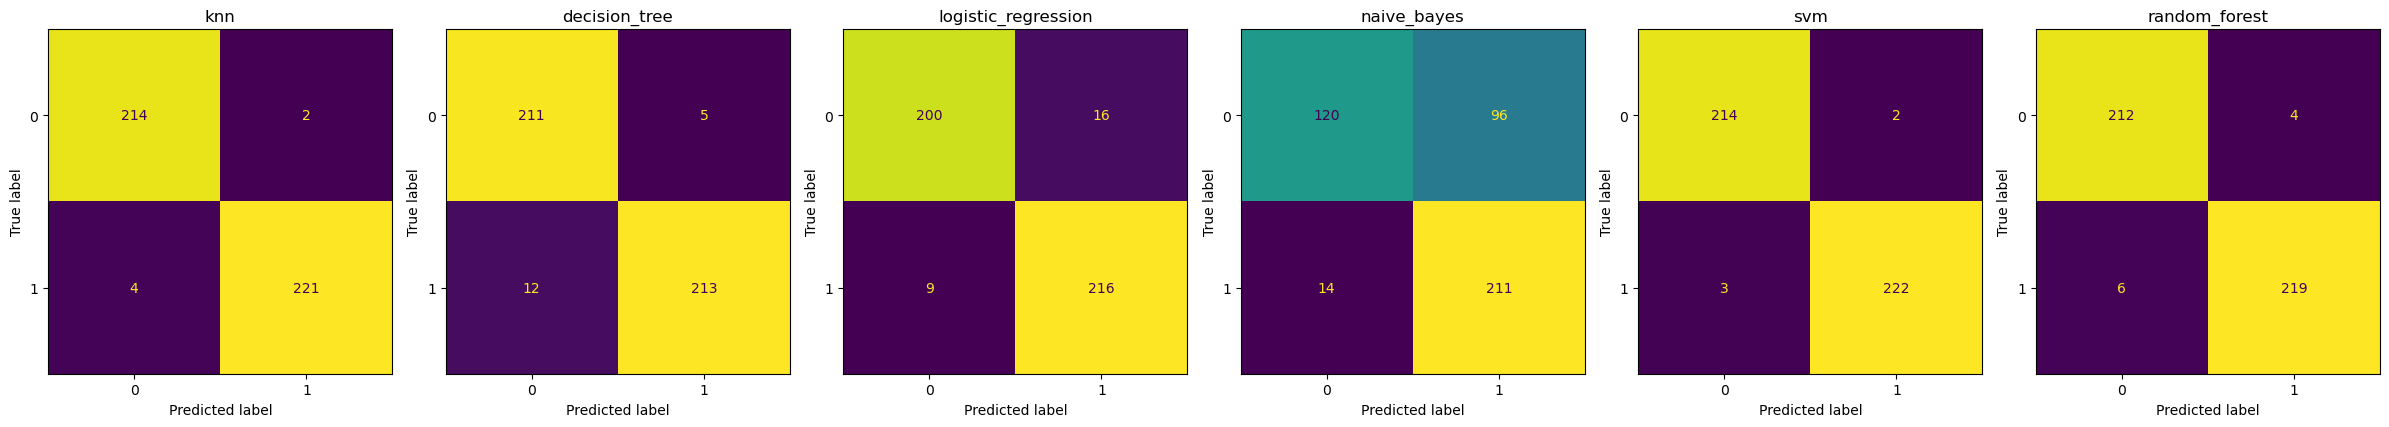

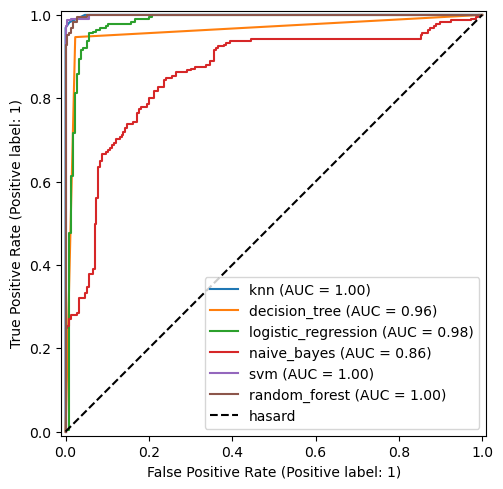

In [7]:
plot_confusion_matrices(tuned, x_test, y_test, save_as="matrices_confusion_mixte.png")
plot_roc_curves(tuned, x_test, y_test, save_as="courbes_roc_mixt.png")

In [4]:
from src.utils import save_models, load_model
save_models(tuned)

model = load_model("random_forest")  
pred = model.predict(x_test)